In [18]:
import numpy as np
import pandas as pd
import torch as torch


In [19]:
df = pd.read_csv("/home/entr0py/Python/ai-ml-log/neural_network/andrej_karapathy_zero_to_hero/makemore/Indian_Names.csv")
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df.head()


,Name
0,aabid
1,aabida
2,aachal
3,aadesh
4,aadil


In [20]:
name = [
    ''.join(c for c in str(w).lower() if 'a' <= c <= 'z')
    for w in df['Name'].dropna()
]
name = [w for w in name if w and len(set(w)) > 1]


In [21]:
name[:5]


['aabid', 'aabida', 'aachal', 'aadesh', 'aadil']

In [22]:
len(name)


6484

In [23]:
min(len(w) for w in name), max(len(w) for w in name)


(2, 15)

In [24]:
b = {}

for w in name:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1


In [25]:
sorted(b.items(), key=lambda kv: kv[1], reverse=True)


[(('a', '<E>'), 1558),
 (('a', 'n'), 1402),
 (('s', 'h'), 1237),
 (('<S>', 's'), 1225),
 (('h', 'a'), 1171),
 (('r', 'a'), 1015),
 (('a', 'r'), 933),
 (('i', '<E>'), 919),
 (('n', 'a'), 713),
 (('a', 'm'), 659),
 (('m', 'a'), 630),
 (('n', '<E>'), 626),
 (('s', 'a'), 605),
 (('<S>', 'a'), 588),
 (('r', '<E>'), 574),
 (('<S>', 'r'), 551),
 (('a', 'l'), 550),
 (('<S>', 'm'), 550),
 (('e', 'e'), 503),
 (('i', 'n'), 479),
 (('h', 'i'), 422),
 (('h', '<E>'), 409),
 (('a', 's'), 404),
 (('n', 'd'), 403),
 (('k', 'a'), 401),
 (('<S>', 'b'), 398),
 (('r', 'i'), 396),
 (('l', '<E>'), 393),
 (('t', 'a'), 388),
 (('l', 'a'), 384),
 (('a', 't'), 383),
 (('<S>', 'k'), 380),
 (('<S>', 'p'), 379),
 (('y', 'a'), 372),
 (('<S>', 'n'), 360),
 (('m', '<E>'), 346),
 (('j', 'a'), 344),
 (('n', 'i'), 325),
 (('e', 'n'), 318),
 (('p', 'a'), 317),
 (('d', 'e'), 313),
 (('e', 'r'), 306),
 (('t', '<E>'), 304),
 (('<S>', 'j'), 297),
 (('<S>', 'd'), 296),
 (('a', 'j'), 290),
 (('u', '<E>'), 288),
 (('i', 's'), 28

In [38]:
N = torch.zeros((28, 28), dtype=torch.int32)
chars = sorted(list(set(''.join(name))))
stoi = {s:i+1 for i, s in enumerate(chars)}
itos = {i: s for s, i in stoi.items()}
itos[0] = '.'
stoi['.'] = 0
stoi

{'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26,
 '.': 0}

In [39]:
for w in name:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

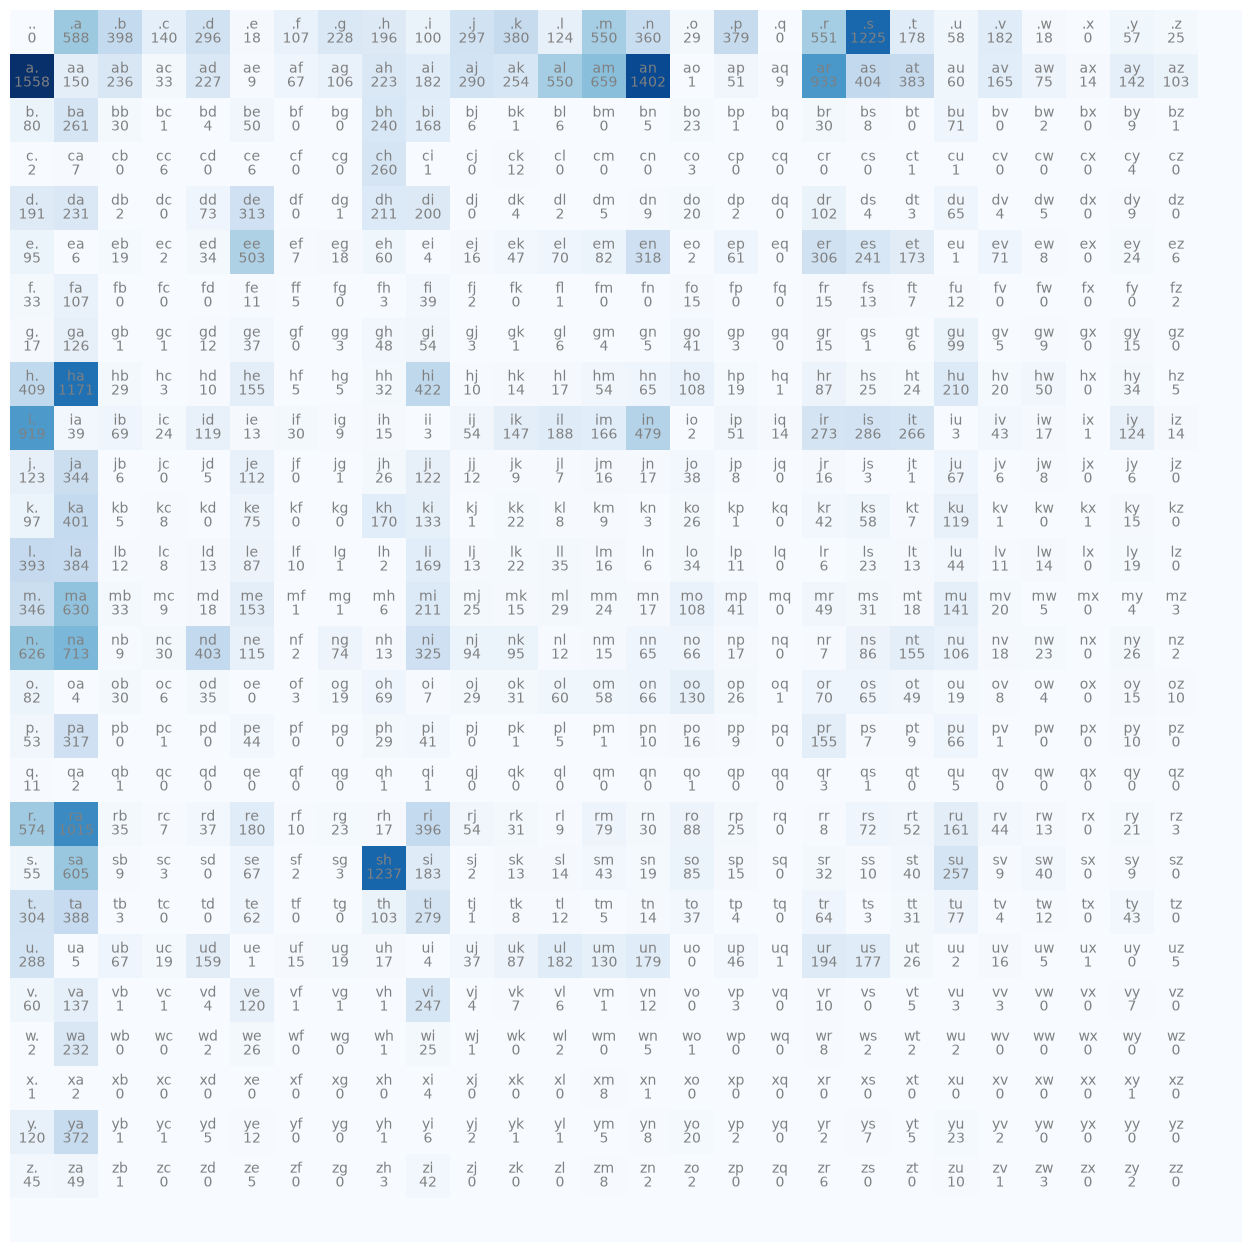

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 16))
plt.imshow(N, cmap='Blues')

for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')

plt.axis('off')

In [55]:
# 1. Correctly initialize the generator
g = torch.Generator()
g.manual_seed(2147483647)

# 2. Get the row, convert to float, and normalize to sum to 1.0
p = N[0, :].float()
p = p / p.sum()

# 3. Sample using multinomial
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
itos[ix]


'd'